<a href="https://colab.research.google.com/github/psh-computer/Machine-Learning/blob/main/day03_2_student_v1_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ---------------------------------------------
# [S0-1] 패키지 설치 (버전 고정)
# ---------------------------------------------
# huggingface-hub : 모델 허브 연동
# tqdm : 진행 바 출력
!pip install -q \
  huggingface-hub==0.23.4 \
  tqdm==4.66.4

# 한글 폰트
!apt-get install -y fonts-nanum > /dev/null 2>&1
print('패키지 설치 완료')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 402.6/402.6 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.3/78.3 kB 8.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
peft 0.21.1 requires huggingface-hub>=0.25.0, but you have huggingface-hub 0.23.4 which is incompatible.
dataproc-spark-connect 1.1.0 requires tqdm>=4.67, but you have tqdm 4.66.4 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.23.4 which is incompatible.
transformers 5.18.0 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.23.4 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 0.23.4 which is incompatible.
gradio 6.29.0 requires huggingface-hu

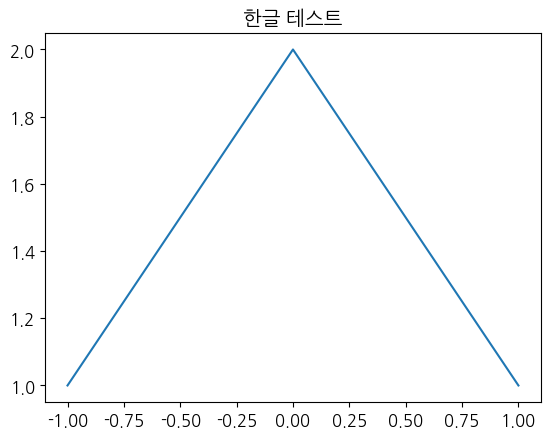

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

# 설치된 나눔길 찾기 및 캐시 업데이트
fe = fm.FontEntry(
    fname=r'/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
    name='NanumGothic'
)

fm.fontManager.ttflist.insert(0, fe)
plt.rcParams.update({'font.size': 12, 'font.family': 'NanumGothic'})

plt.title('한글 테스트')
plt.plot([-1, 0, 1], [1, 2, 1])
plt.show()

In [ ]:
import torch
import torch.nn.functional as F
from tqdm import tqdm
import time

# tqdm : 반복문에 프로그레스바를 붙여주는 라이브러리
# DataLoader처럼 오래 걸리는 루프에 얼마나 남았는지 보여줌

items = list(range(10))

for item in tqdm (items, desc='처리 중'):
  time.sleep(0.1)    # 실제 작업 대신 잠깐 대기

print('tqdm 확인 완료')

처리 중: 100%|██████████| 10/10 [00:01<00:00,  9.76it/s]

tqdm 확인 완료


In [ ]:
# tqpk : 텐서에서 가장 큰 k개를 뽑아줌
# kNN에서 가장 유사한 k개 이웃을 찾을 때 사용

scores = torch.tensor([0.12, 0.91, 0.08, 0.45, 0.03])
print("원본 :", scores)

result = scores.topk(k=3)
print("top-3 값    :", result.values)  # 큰 순서대로 3개
print("top-3 인덱스 :", result.indices) # 해당 위치

# 2D 텐서 (여러 샘플) - dim = 1 : 각 행에서 top-k
sim_matrix = torch.tensor([
    [0.91, 0.12, 0.08, 0.05],   # test 샘플 0의 유사도
    [0.10, 0.88, 0.11, 0.06]    # test 샘플 1의 유사도
])

print('\n 유사도 행렬 (2, 4):\n', sim_matrix)

topk_result = sim_matrix.topk(k=2, dim=1)
print('top-2 인덱스 \n', topk_result.indices) # (2, 2)
print('toqk 확인 완료')

원본 : tensor([0.1200, 0.9100, 0.0800, 0.4500, 0.0300])
top-3 값    : tensor([0.9100, 0.4500, 0.1200])
top-3 인덱스 : tensor([1, 3, 0])

 유사도 행렬 (2, 4):
 tensor([[0.9100, 0.1200, 0.0800, 0.0500],
        [0.1000, 0.8800, 0.1100, 0.0600]])
top-2 인덱스 
 tensor([[0, 1],
        [1, 2]])
toqk 확인 완료


In [ ]:
# ------------------------------------------
# SEED 고정 + device + 전역 상수
# ------------------------------------------
import os
import random
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torchvision.models as models

from PIL import Image, ImageFilter
from tqdm import tqdm
# 재현성 확보
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

# 장치 선택
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 하이퍼파라미터 상수
IMG_SIZE        = 96        # STL-10 기본 해상도 (96X96)
BATCH_SIZE      = 256       # SSL 배치 크기 (클수로 NT_Xent 성능 올라감)
NUM_WORKERS     = 2         # DataLoader 병령 프로세스 수
PROJ_DIM        = 128       # Projection Head 출력 지원
FEAT_DIM        = 512       # ResNet-18 encoder 출력 지원

# 정규화 상수 (ImageNet 기준)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGE_STD     = [0.229, 0.224, 0.225]

print(f'device        : {device}')
print(f'IMG_SIZE      : {IMG_SIZE}')
print(f'BATCH_SIZE    : {BATCH_SIZE}')
print(f'PROJ_DIM      : {PROJ_DIM}')

device        : cuda
IMG_SIZE      : 96
BATCH_SIZE    : 256
PROJ_DIM      : 128


In [ ]:
import random

from PIL import Image, ImageFilter
from torch.utils.data import Dataset
from torchvision import transforms


class GaussianBlur:
    """PIL 기반 Gaussian Blur."""

    def __init__(self, sigma: tuple = (0.1, 2.0)):
        self.sigma = sigma

    def __call__(self, img: Image.Image) -> Image.Image:
        sigma = random.uniform(self.sigma[0], self.sigma[1])
        return img.filter(ImageFilter.GaussianBlur(radius=sigma))


class TwoCropsTransform:
    """동일한 이미지에 Transform을 독립적으로 두 번 적용."""

    def __init__(self, base_transform: transforms.Compose):
        self.base_transform = base_transform

    def __call__(self, img: Image.Image):
        view1 = self.base_transform(img)
        view2 = self.base_transform(img)

        return view1, view2


class SSLDataset(Dataset):
    """Unlabeled Dataset에 TwoCropsTransform을 적용하는 래퍼."""

    def __init__(self, stl10_dataset, transform: TwoCropsTransform):
        self.dataset = stl10_dataset
        self.transform = transform

    def __len__(self) -> int:
        return len(self.dataset)

    def __getitem__(self, idx: int):
        img, _ = self.dataset[idx]
        return self.transform(img)


ssl_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.2, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply(
        [
            transforms.ColorJitter(
                brightness=0.4,
                contrast=0.4,
                saturation=0.2,
                hue=0.1
            )
        ],
        p=0.8
    ),
    transforms.RandomGrayscale(p=0.2),
    transforms.RandomApply(
        [GaussianBlur(sigma=(0.1, 2.0))],
        p=0.4
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGE_STD)
])


eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGE_STD)
])

In [ ]:
DATA_ROOT = "./data"

stl_unlabeled = datasets.STL10(DATA_ROOT, split = "unlabeled", download=True)
stl_train     = datasets.STL10(DATA_ROOT, split = "train", download=True)
stl_test      = datasets.STL10(DATA_ROOT, split = "test", download=True)

ssl_dataset = SSLDataset(
    stl10_dataset = stl_unlabeled,
    transform     = TwoCropsTransform(ssl_transform)
)

ssl_loader = DataLoader(
    ssl_dataset,
    batch_size  = BATCH_SIZE,
    shuffle     = True,
    num_workers = NUM_WORKERS,
    drop_last   = True,
    pin_memory  = True
)

lin_train_dataset = datasets.STL10(DATA_ROOT, split='train', download=False,
                                   transform = eval_transform)
lin_test_dataset  = datasets.STL10(DATA_ROOT, split='test',  download=False,
                                   transform = eval_transform)
lin_train_loader  = DataLoader(lin_train_dataset, batch_size = BATCH_SIZE,
                               shuffle = True, num_workers = NUM_WORKERS, pin_memory = True)
lin_test_loader  = DataLoader(lin_test_dataset, batch_size = BATCH_SIZE,
                               shuffle = True, num_workers = NUM_WORKERS, pin_memory = True)


print(f'ssl_loader          : {len(ssl_loader)} 배치')
print(f'ssl_train_loader    : {len(lin_train_loader)} 배치')
print(f'ssl_test_loader     : {len(lin_test_loader)} 배치')


100%|██████████| 2.64G/2.64G [06:47<00:00, 6.48MB/s]


ssl_loader          : 390 배치
ssl_train_loader    : 20 배치
ssl_test_loader     : 32 배치


In [ ]:
class SimCLRNet(nn.Module):
  """
  SimCLR 전체 모델:
    encoder   : ResNet-18(fc 제거) -> 512-d
    projector : 2-layer MLP -> L2 정규화된 123-d
  """

  def __init__ (self, base_model: nn.Module, proj_dim: int = 128):
    super().__init__()
    self.encoder    = base_model
    self.projector  = nn.Sequential(
        nn.Linear(FEAT_DIM, FEAT_DIM),
        nn.BatchNorm1d(FEAT_DIM),
        nn.ReLU(inplace=True),
        nn.Linear(FEAT_DIM, proj_dim)
    )

  def forward(self, x:torch.Tensor) -> torch.Tensor:
    h = self.encoder(x)               # (B, 512)
    z = self.projector(h)             # (B, 128)
    return F.normalize(z, dim=1)      # L2 정규화 -> (B, 128)


def build_simclr() -> SimCLRNet:
    backbone    = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    backbone.fc = nn.Identity()
    return SimCLRNet(backbone, PROJ_DIM)

model = build_simclr().to(device)

total_parmas = sum(p.numel() for p in model.parameters())
print(f'전체 파라미터 수 : {total_parmas:,}')

with torch.no_grad():
  dummy = torch.randn(4, 3, IMG_SIZE, IMG_SIZE).to(device)
  z_out = model(dummy)
  print(f'forward 출력 shape : {z_out.shape}    # (B=4, D=128)')
  print(f'L2 norm 확인       : {z_out.norm(dim=1).mean():.4f}  # = 1.0000')

  print()
  print('완료')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 112MB/s]


전체 파라미터 수 : 11,505,856
forward 출력 shape : torch.Size([4, 128])    # (B=4, D=128)
L2 norm 확인       : 1.0000  # = 1.0000

완료


In [ ]:
def ntxent_loss(z1: torch.Tensor, z2: torch.Tensor, temperature:float = 0.2) -> torch.Tensor:
  """
  NT-Xent (InfoNCE) Loss 구현

  Args:
    z1, z2    : (B, D) - SimCLRNet 출력 (이미 L2 정규화 완료)
    temperature: float (권장: 0.2)

  Returns:
    scalar loss
  """

  B = z1.size(0)

  # Step1 : batch 차원(dim=0)으로 이어붙이기 -> (2B, D)
  z = torch.cat([z1, z2], dim=0)
  print(f'\n[cat] z = cat([z1, z2]), dim - 0 --> {z.shape}  # (2B, D) = (4, 4)')

  # Step2 : cosine similarity 행렬 (L2 정규화된 z이면 내적 = cosine)
  sim = z @ z.T / temperature  # (2B, 2B)
  print(f'[matmul] sim = z @ z.T / temperature --> {sim.shape}  # (2B, 2B)')

  # Step3 : 자기 자신과의 유사도는 softmax에서 항상 최대 --> inf로 제거
  mask = torch.eye(2*B, dtype=torch.bool)   # (2B, 2B) 대각 True
  print('mask:', mask)
  sim_masked = sim.masked_fill(mask, float('-inf'))
  print(f'[eye+masked_fill] 대각 제거 후 sim[0, 0] = {sim_masked[0, 0]} (should be -inf)')

  # Step4 : positive 인덱스 - z1_i의 짝은 z2_1 --> 인덱스 i+B
  pos_idx = torch.cat([torch.arange(B, 2*B), torch.arange(B)])
  print(f'\n [arange+cat] pos_idx = {pos_idx.tolist()}')
  print(" 의미: 행이(z1_0)의 정답 열=2(z2_0), 행 1 -> 3, 행2 (z2_0)->0(z2_0), 행 3->1")

  # Step5 : 행마다 하나의 정답 클래스를 고르는 corss_entropy
  loss = F.cross_entropy(sim_masked, pos_idx)
  print(f'\n [cross_entropy] NT-Xent 스타일 loss = {loss.item():.4f}')


Device: cuda


100%|██████████| 2.64G/2.64G [07:37<00:00, 5.77MB/s]


Unlabeled train images: 100000
Labeled train images  : 5000
Test images           : 8000

Augmentation: blur_only
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 129MB/s]


[blur_only] Epoch  1/10 | Loss 1.1350 | kNN 45.12% | Linear Probe 37.79%
[blur_only] Epoch  5/10 | Loss 1.0383 | kNN 43.00% | Linear Probe 34.30%
[blur_only] Epoch 10/10 | Loss 1.0349 | kNN 43.25% | Linear Probe 33.76%

Augmentation: color_blur
[color_blur] Epoch  1/10 | Loss 1.1685 | kNN 47.84% | Linear Probe 44.46%
[color_blur] Epoch  5/10 | Loss 1.0531 | kNN 47.31% | Linear Probe 43.13%
[color_blur] Epoch 10/10 | Loss 1.0469 | kNN 47.05% | Linear Probe 42.70%

Augmentation: crop_gray_color_blur
[crop_gray_color_blur] Epoch  1/10 | Loss 2.7923 | kNN 56.04% | Linear Probe 59.73%
[crop_gray_color_blur] Epoch  5/10 | Loss 2.0237 | kNN 66.16% | Linear Probe 68.91%
[crop_gray_color_blur] Epoch 10/10 | Loss 1.8460 | kNN 68.94% | Linear Probe 71.80%

전체 결과:


,augmentation,epoch,pretrain_loss,knn_top1,linear_probe_top1
0,blur_only,1,1.135022,0.451250,0.377875
1,blur_only,5,1.038301,0.430000,0.343000
2,blur_only,10,1.034929,0.432500,0.337625
3,color_blur,1,1.168494,0.478375,0.444625
4,color_blur,5,1.053095,0.473125,0.431250
5,color_blur,10,1.046866,0.470500,0.427000
6,crop_gray_color_blur,1,2.792346,0.560375,0.597250
7,crop_gray_color_blur,5,2.023678,0.661625,0.689125
8,crop_gray_color_blur,10,1.845977,0.689375,0.718000



CSV 저장 위치: /content/simclr_experiments/results.csv
체크포인트 저장 위치: /content/simclr_experiments


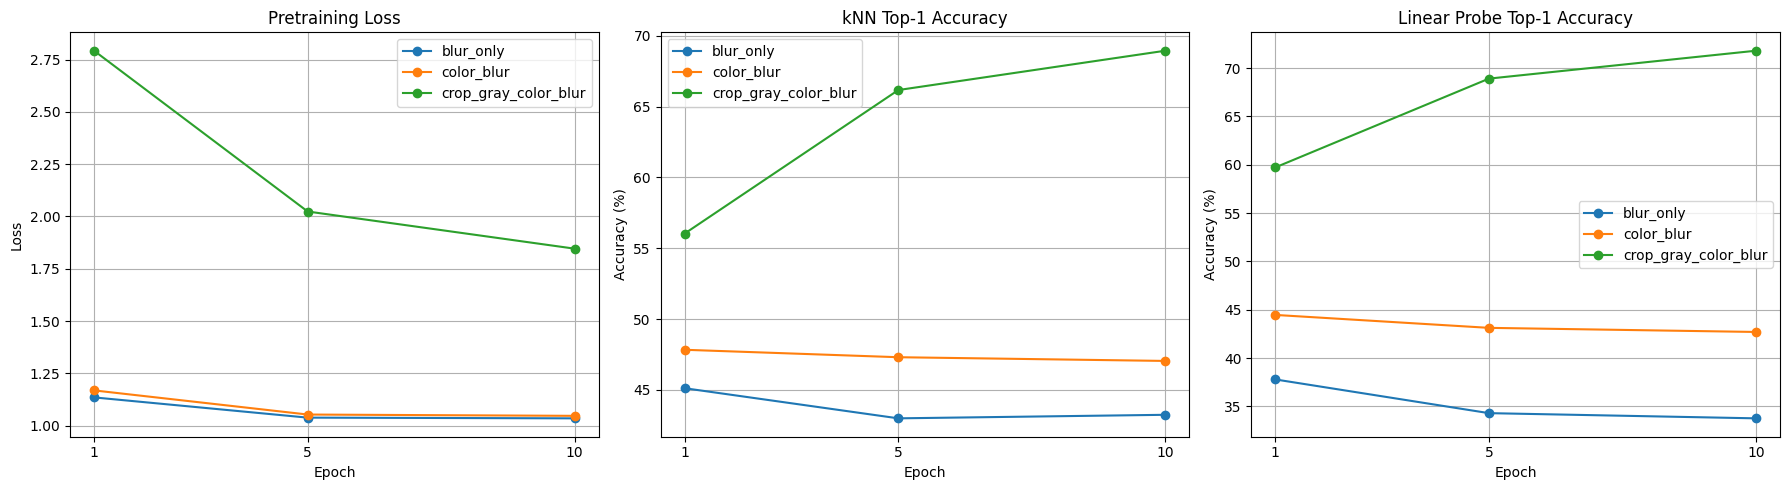

In [ ]:
import csv
import os
import random

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import ImageFilter
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, models, transforms


# ============================================================
# 1. 설정
# ============================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

DATA_ROOT = "/content/data"
RESULT_DIR = "/content/simclr_experiments"
os.makedirs(RESULT_DIR, exist_ok=True)

SEED = 42

IMG_SIZE = 96
FEAT_DIM = 512
PROJ_DIM = 128

BATCH_SIZE = 128
NUM_WORKERS = 2

# 사전학습 epoch
EPOCHS = 10

# 1, 5, 10 epoch에서 평가
EVAL_EVERY = 5

# SimCLR NT-Xent temperature
PRETRAIN_TEMP = 0.2

# kNN 설정
KNN_K = 200
KNN_TEMP = 0.07

# Linear Probe 학습 설정
LINEAR_EVAL_EPOCHS = 100
LINEAR_EVAL_BATCH_SIZE = 256
LINEAR_EVAL_LR = 0.1
LINEAR_EVAL_SEED = 1234

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGE_STD = (0.229, 0.224, 0.225)

AUGMENTATIONS = (
    "blur_only",
    "color_blur",
    "crop_gray_color_blur",
)

EVAL_EPOCHS = {1, 5, 10}


def set_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ============================================================
# 2. SimCLR 모델과 augmentation
# ============================================================

class GaussianBlur:
    """PIL 이미지에 랜덤 세기의 Gaussian Blur를 적용합니다."""

    def __init__(self, kernel_size=23, sigma=(0.1, 2.0)):
        self.kernel_size = kernel_size
        self.sigma = sigma

    def __call__(self, image):
        radius = random.uniform(self.sigma[0], self.sigma[1])
        return image.filter(ImageFilter.GaussianBlur(radius=radius))


class TwoCropsTransform:
    """한 이미지에 augmentation을 독립적으로 두 번 적용합니다."""

    def __init__(self, base_transform):
        self.base_transform = base_transform

    def __call__(self, image):
        return self.base_transform(image), self.base_transform(image)


class SSLDataset(Dataset):
    """STL-10 unlabeled 이미지를 두 개의 view로 반환합니다."""

    def __init__(self, stl10_dataset, transform):
        self.dataset = stl10_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, _ = self.dataset[idx]
        return self.transform(image)


class SimCLRNet(nn.Module):
    """ResNet-18 encoder와 2-layer projection head."""

    def __init__(self, base_model, proj_dim=PROJ_DIM):
        super().__init__()
        self.encoder = base_model
        self.projector = nn.Sequential(
            nn.Linear(FEAT_DIM, FEAT_DIM),
            nn.BatchNorm1d(FEAT_DIM),
            nn.ReLU(inplace=True),
            nn.Linear(FEAT_DIM, proj_dim),
        )

    def forward(self, x):
        h = self.encoder(x)
        z = self.projector(h)
        return F.normalize(z, dim=1)


def build_simclr():
    # 세 augmentation 실험은 모두 같은 ImageNet pretrained ResNet-18에서 시작합니다.
    backbone = models.resnet18(
        weights=models.ResNet18_Weights.IMAGENET1K_V1
    )
    backbone.fc = nn.Identity()
    return SimCLRNet(backbone, PROJ_DIM)


def make_ssl_transform(augmentation):
    """
    비교할 세 조건:
      blur_only             : Blur만 적용
      color_blur            : Color Jitter + Blur
      crop_gray_color_blur  : Crop + Flip + Grayscale + Color Jitter + Blur
    """
    ops = []

    if augmentation == "crop_gray_color_blur":
        ops.extend([
            transforms.RandomResizedCrop(
                IMG_SIZE, scale=(0.2, 1.0)
            ),
            transforms.RandomHorizontalFlip(p=0.5),
        ])

    if augmentation in ("color_blur", "crop_gray_color_blur"):
        ops.append(
            transforms.RandomApply(
                [
                    transforms.ColorJitter(
                        brightness=0.4,
                        contrast=0.4,
                        saturation=0.2,
                        hue=0.1,
                    )
                ],
                p=0.8,
            )
        )

    if augmentation == "crop_gray_color_blur":
        ops.append(transforms.RandomGrayscale(p=0.2))

    if augmentation in AUGMENTATIONS:
        ops.append(
            transforms.RandomApply(
                [GaussianBlur(kernel_size=23)],
                p=0.4,
            )
        )
    else:
        raise ValueError(f"알 수 없는 augmentation: {augmentation}")

    # PIL 기반 augmentation 후 Tensor 변환과 정규화를 적용합니다.
    ops.extend([
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGE_STD),
    ])

    return transforms.Compose(ops)


# 평가 데이터에는 랜덤 augmentation을 적용하지 않습니다.
eval_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGE_STD),
])


# ============================================================
# 3. STL-10 데이터
# ============================================================

stl_unlabeled = datasets.STL10(
    DATA_ROOT,
    split="unlabeled",
    download=True,
)

lin_train_dataset = datasets.STL10(
    DATA_ROOT,
    split="train",
    download=True,
    transform=eval_transform,
)

lin_test_dataset = datasets.STL10(
    DATA_ROOT,
    split="test",
    download=True,
    transform=eval_transform,
)

PIN_MEMORY = torch.cuda.is_available()

lin_train_loader = DataLoader(
    lin_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

lin_test_loader = DataLoader(
    lin_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

print(f"Unlabeled train images: {len(stl_unlabeled)}")
print(f"Labeled train images  : {len(lin_train_dataset)}")
print(f"Test images           : {len(lin_test_dataset)}")


# ============================================================
# 4. Loss와 optimizer
# ============================================================

def ntxent_loss(z1, z2, temperature=PRETRAIN_TEMP):
    """대칭 NT-Xent loss. z1, z2는 L2 정규화된 출력입니다."""
    batch_size = z1.size(0)
    z = torch.cat([z1, z2], dim=0)

    logits = (z @ z.T) / temperature

    self_mask = torch.eye(
        2 * batch_size,
        dtype=torch.bool,
        device=z.device,
    )
    logits = logits.masked_fill(self_mask, float("-inf"))

    targets = torch.cat([
        torch.arange(batch_size, 2 * batch_size, device=z.device),
        torch.arange(0, batch_size, device=z.device),
    ])

    return F.cross_entropy(logits, targets)


def make_pretrain_optimizer(model):
    # 실험 간 동일한 optimizer와 hyperparameter를 사용합니다.
    # 논문 기본 설정의 LARS와는 다른 SGD 설정입니다.
    learning_rate = 0.3 * BATCH_SIZE / 256

    return torch.optim.SGD(
        model.parameters(),
        lr=learning_rate,
        momentum=0.9,
        weight_decay=1e-6,
    )


# ============================================================
# 5. Feature 추출과 평가
# ============================================================

@torch.inference_mode()
def extract_features(encoder, loader):
    encoder.eval()

    feature_batches = []
    label_batches = []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        features = encoder(images)

        if features.ndim > 2:
            features = torch.flatten(
                F.adaptive_avg_pool2d(features, 1),
                start_dim=1,
            )

        feature_batches.append(features.float())
        label_batches.append(labels.to(DEVICE))

    return torch.cat(feature_batches), torch.cat(label_batches)


@torch.inference_mode()
def knn_accuracy(train_x, train_y, test_x, test_y):
    """Cosine similarity와 temperature 가중 투표로 kNN top-1 accuracy를 구합니다."""
    train_x = F.normalize(train_x, dim=1)
    test_x = F.normalize(test_x, dim=1)

    k = min(KNN_K, len(train_x))
    correct = 0
    total = 0

    for start in range(0, len(test_x), 512):
        query_x = test_x[start:start + 512]
        similarities = query_x @ train_x.T

        values, indices = similarities.topk(k, dim=1)
        neighbor_labels = train_y[indices]
        weights = torch.exp(values / KNN_TEMP)

        class_scores = torch.zeros(
            len(values),
            10,
            device=DEVICE,
        )
        class_scores.scatter_add_(
            dim=1,
            index=neighbor_labels,
            src=weights,
        )

        predictions = class_scores.argmax(dim=1)
        targets = test_y[start:start + len(predictions)]

        correct += (predictions == targets).sum().item()
        total += len(targets)

    return correct / total


def linear_probe_accuracy(train_x, train_y, test_x, test_y):
    """Encoder feature를 고정하고 단일 선형 분류기만 학습합니다."""
    head = nn.Linear(train_x.shape[1], 10).to(DEVICE)

    optimizer = torch.optim.SGD(
        head.parameters(),
        lr=LINEAR_EVAL_LR,
        momentum=0.9,
        weight_decay=0.0,
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=LINEAR_EVAL_EPOCHS,
    )

    for _ in range(LINEAR_EVAL_EPOCHS):
        head.train()

        order = torch.randperm(len(train_x), device=DEVICE)

        for indices in order.split(LINEAR_EVAL_BATCH_SIZE):
            logits = head(train_x[indices])
            loss = F.cross_entropy(logits, train_y[indices])

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

        scheduler.step()

    head.eval()

    with torch.inference_mode():
        predictions = head(test_x).argmax(dim=1)
        accuracy = (predictions == test_y).float().mean().item()

    return accuracy


def evaluate_encoder(model):
    # 평가가 다음 사전학습 epoch의 RNG 흐름을 바꾸지 않도록 분리합니다.
    cuda_devices = (
        [torch.cuda.current_device()]
        if torch.cuda.is_available()
        else []
    )

    with torch.random.fork_rng(devices=cuda_devices):
        torch.manual_seed(LINEAR_EVAL_SEED)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(LINEAR_EVAL_SEED)

        train_x, train_y = extract_features(
            model.encoder,
            lin_train_loader,
        )
        test_x, test_y = extract_features(
            model.encoder,
            lin_test_loader,
        )

        knn_acc = knn_accuracy(
            train_x, train_y, test_x, test_y
        )
        linear_acc = linear_probe_accuracy(
            train_x, train_y, test_x, test_y
        )

    return knn_acc, linear_acc


# ============================================================
# 6. Augmentation별 사전학습 및 epoch별 평가
# ============================================================

def run_experiment(augmentation):
    print(f"\n{'=' * 65}")
    print(f"Augmentation: {augmentation}")
    print(f"{'=' * 65}")

    # 매 실험을 같은 seed와 같은 pretrained encoder에서 시작합니다.
    set_seed(SEED)

    ssl_dataset = SSLDataset(
        stl_unlabeled,
        TwoCropsTransform(
            make_ssl_transform(augmentation)
        ),
    )

    ssl_loader = DataLoader(
        ssl_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        drop_last=True,
        pin_memory=PIN_MEMORY,
    )

    model = build_simclr().to(DEVICE)
    optimizer = make_pretrain_optimizer(model)

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS,
    )

    rows = []

    for epoch in range(1, EPOCHS + 1):
        model.train()

        loss_sum = 0.0
        num_batches = 0

        for view1, view2 in ssl_loader:
            view1 = view1.to(DEVICE, non_blocking=True)
            view2 = view2.to(DEVICE, non_blocking=True)

            z1 = model(view1)
            z2 = model(view2)

            loss = ntxent_loss(z1, z2)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item()
            num_batches += 1

        scheduler.step()
        mean_loss = loss_sum / max(num_batches, 1)

        # Epoch 1, 5, 10에서 평가하고 결과를 출력합니다.
        if epoch == 1 or epoch % EVAL_EVERY == 0:
            knn_acc, linear_acc = evaluate_encoder(model)

            row = {
                "augmentation": augmentation,
                "epoch": epoch,
                "pretrain_loss": mean_loss,
                "knn_top1": knn_acc,
                "linear_probe_top1": linear_acc,
            }
            rows.append(row)

            checkpoint_path = os.path.join(
                RESULT_DIR,
                f"{augmentation}_epoch_{epoch}.pt",
            )
            torch.save(model.state_dict(), checkpoint_path)

            print(
                f"[{augmentation}] "
                f"Epoch {epoch:2d}/{EPOCHS} | "
                f"Loss {mean_loss:.4f} | "
                f"kNN {knn_acc * 100:.2f}% | "
                f"Linear Probe {linear_acc * 100:.2f}%"
            )

    return rows


# ============================================================
# 7. 세 실험 실행, CSV 저장, 그래프 출력
# ============================================================

all_results = []

for augmentation in AUGMENTATIONS:
    all_results.extend(run_experiment(augmentation))

csv_path = os.path.join(RESULT_DIR, "results.csv")

with open(csv_path, "w", newline="", encoding="utf-8") as file:
    fieldnames = [
        "augmentation",
        "epoch",
        "pretrain_loss",
        "knn_top1",
        "linear_probe_top1",
    ]
    writer = csv.DictWriter(file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(all_results)

results_df = pd.DataFrame(all_results)

print("\n전체 결과:")
display(results_df)

print(f"\nCSV 저장 위치: {csv_path}")
print(f"체크포인트 저장 위치: {RESULT_DIR}")


# Loss, kNN, Linear Probe 결과 그래프
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for augmentation in AUGMENTATIONS:
    subset = results_df[
        results_df["augmentation"] == augmentation
    ]

    axes[0].plot(
        subset["epoch"],
        subset["pretrain_loss"],
        marker="o",
        label=augmentation,
    )
    axes[1].plot(
        subset["epoch"],
        subset["knn_top1"] * 100,
        marker="o",
        label=augmentation,
    )
    axes[2].plot(
        subset["epoch"],
        subset["linear_probe_top1"] * 100,
        marker="o",
        label=augmentation,
    )

axes[0].set_title("Pretraining Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[1].set_title("kNN Top-1 Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")

axes[2].set_title("Linear Probe Top-1 Accuracy")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.set_xticks([1, 5, 10])
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()